# Chapter 6: Time-Series Visualization with Python

## 1. Introduction

Visualization helps us understand patterns in time-series data that may not be obvious from tables alone. Line charts can reveal trends, fluctuations, unusual observations, and changes over time.

This chapter uses pandas and Matplotlib to visualize time-dependent data.

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
```

## 2. Basic Time-Series Plots

A pandas Series with a `DatetimeIndex` can be plotted directly.

```python
df["temperature"].plot(figsize=(12, 5))

plt.title("Temperature Over Time")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.grid(True)

plt.show()
```

- `.plot()` creates a line plot.
- `figsize=(12, 5)` sets the figure dimensions in inches.
- `plt.title()` adds a chart title.
- `plt.xlabel()` and `plt.ylabel()` label the axes.
- `plt.grid(True)` displays gridlines.
- `plt.show()` displays the plot.

A time-series line chart uses time on the x-axis and the measured variable on the y-axis.

## 3. Figure and Axes Objects

Matplotlib provides an object-oriented plotting interface that is especially useful when creating multiple charts.

```python
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df.index, df["temperature"], label="Temperature")

ax.set_title("Temperature Over Time")
ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")
ax.legend()
ax.grid(True)

plt.show()
```

- `fig` represents the entire figure or canvas.
- `ax` represents one plotting area, including its axes, title, labels, and plotted data.
- `ax.plot()` plots data on that Axes.
- `ax.legend()` displays labels assigned to plotted series.

The object-oriented approach provides greater control over individual charts and is convenient for more complex visualizations.

## 4. Plotting Multiple Time Series

Multiple variables can be plotted on the same chart.

```python
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df.index, df["temperature"], label="Temperature")
ax.plot(df.index, df["pressure"], label="Pressure")

ax.set_title("Temperature and Pressure Over Time")
ax.set_xlabel("Time")
ax.set_ylabel("Measured Value")
ax.legend()
ax.grid(True)

plt.show()
```

The `label` argument assigns a name to each series, while `legend()` displays those names.

However, variables measured in different units should not be compared casually on the same y-axis. Temperature and pressure, for example, may be easier to interpret using separate subplots.

## 5. Subplots

Subplots allow multiple charts to appear within a single figure.

```python
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True
)

axes[0].plot(df.index, df["temperature"])
axes[0].set_title("Temperature Over Time")
axes[0].set_ylabel("Temperature (°C)")
axes[0].grid(True)

axes[1].plot(df.index, df["pressure"])
axes[1].set_title("Pressure Over Time")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Pressure")
axes[1].grid(True)

plt.tight_layout()
plt.show()
```

Here, `axes` is an array of Axes objects.

- `axes[0]` refers to the first subplot.
- `axes[1]` refers to the second subplot.
- `nrows=2, ncols=1` creates two vertically stacked charts.
- `nrows=1, ncols=2` creates two charts side by side.
- `sharex=True` shares the horizontal axis between subplots.
- `sharey=True` shares the vertical axis.

Shared axes are useful when comparing variables across the same time period. Sharing the y-axis is most appropriate when the variables have comparable units and scales.

`plt.tight_layout()` adjusts spacing to reduce overlap between titles, labels, and charts.

## 6. Visualizing Rolling Statistics

Rolling statistics can be plotted alongside the original series to show how smoothing affects the data.

```python
df["rolling_mean_3"] = (
    df["temperature"].rolling(window=3).mean()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df.index,
    df["temperature"],
    label="Original Temperature",
    marker="o"
)

ax.plot(
    df.index,
    df["rolling_mean_3"],
    label="3-Observation Rolling Mean"
)

ax.set_title("Temperature and Rolling Mean")
ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()
```

The original series shows individual measurements, while the rolling mean smooths some short-term fluctuations.

A larger window generally produces stronger smoothing but responds more slowly to changes. It also produces more initial `NaN` values when the default minimum number of observations is required.

A rolling mean can help identify recent trends, but excessive smoothing can hide short-lived events or unusual measurements.

**Important:** `window=3` means three observations, not necessarily three hours. It represents three hours only when the observations are regularly spaced one hour apart.

## 7. Comparing Hourly and Daily Data

Resampling converts data from one frequency to another by grouping observations into time intervals and applying an aggregation.

```python
df_daily = df[["temperature"]].resample("D").mean()
```

Here, `"D"` represents daily frequency, and `.mean()` calculates the mean of the observations within each day.

The hourly and daily series can be visualized separately:

```python
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(
    df.index,
    df["temperature"],
    marker="o",
    label="Hourly Temperature"
)
axes[0].set_title("Hourly Temperature")
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    df_daily.index,
    df_daily["temperature"],
    marker="o",
    label="Daily Mean Temperature"
)
axes[1].set_title("Daily Mean Temperature")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Temperature (°C)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()
```

If all six observations occur on one day, the hourly chart contains six points while the daily chart contains one point representing the mean of those six observations.

Resampling can simplify long time series, but it also removes detail. A daily mean may conceal short-lived fluctuations that are visible in hourly data.

A pandas Series and a DataFrame must be handled differently:

```python
# Returns a Series
df_daily = df["temperature"].resample("D").mean()

# Plot the Series directly
ax.plot(df_daily.index, df_daily)
```

Alternatively:

```python
# Returns a DataFrame
df_daily = df[["temperature"]].resample("D").mean()

# Select its temperature column
ax.plot(df_daily.index, df_daily["temperature"])
```

Single brackets select a Series, while double brackets preserve the DataFrame structure.

## 8. Formatting Date Axes

For longer time series, date labels may overlap or become difficult to read. Matplotlib provides date locators and formatters to control tick positions and label formats.

```python
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_long.index, df_long["temperature"])

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.set_title("Monthly Date Formatting")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature")
ax.grid(True)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()
```

Common date-format codes include:

| Format code | Example | Purpose |
|---|---|---|
| `"%d %b"` | `04 Jan` | Day and abbreviated month |
| `"%b %Y"` | `Jan 2026` | Abbreviated month and year |
| `"%Y"` | `2026` | Year |
| `"%H:%M"` | `09:00` | Time of day |
| `"%d-%m-%Y"` | `04-01-2026` | Numeric date |

Useful date locators include:

- `mdates.DayLocator()` for daily tick intervals.
- `mdates.WeekdayLocator()` for ticks on selected weekdays.
- `mdates.MonthLocator()` for monthly ticks.
- `mdates.YearLocator()` for yearly ticks.

`fig.autofmt_xdate()` helps improve the readability of date labels.

## 9. Interpreting Time-Series Charts

Creating a chart is only the first step. The next step is interpreting what it shows.

When analyzing a time-series plot, consider:

1. **Trend:** Is the variable generally increasing or decreasing?
2. **Fluctuations:** How much does the variable change between observations?
3. **Unusual observations:** Are there sudden spikes, drops, or unexpected values?
4. **Smoothing:** Does a rolling statistic reveal a broader pattern?
5. **Frequency:** Does aggregation hide meaningful short-term behavior?
6. **Scale and units:** Are the axes appropriate for the variables being compared?

In chemical engineering, time-series visualization can help monitor reactor temperatures, pressure readings, viscosity, coating properties, and other process variables. Visualizations can support process monitoring, but they do not independently establish the cause of an abnormal measurement.

## 10. Chapter Summary

This chapter covered:

- Basic time-series line plots.
- Matplotlib figures and Axes objects.
- Multiple lines, legends, and markers.
- Subplots and shared axes.
- Visualizing rolling means alongside raw data.
- Comparing hourly observations with daily aggregates.
- Formatting date axes with Matplotlib date locators and formatters.
- Interpreting trends, fluctuations, and the limitations of smoothing.

The main goal is to choose a visualization that makes the time-dependent behavior understandable without concealing important information.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

dates = pd.date_range(
    start = "2026-01-01 09:00",
    periods = 6,
    freq = 'h'
)

df = pd.DataFrame(
    {"temperature":[100, 104, 102, 110, 108, 112]},
    index = dates
)
df.index.name = 'time'
df

,temperature
time,
2026-01-01 09:00:00,100
2026-01-01 10:00:00,104
2026-01-01 11:00:00,102
2026-01-01 12:00:00,110
2026-01-01 13:00:00,108
2026-01-01 14:00:00,112


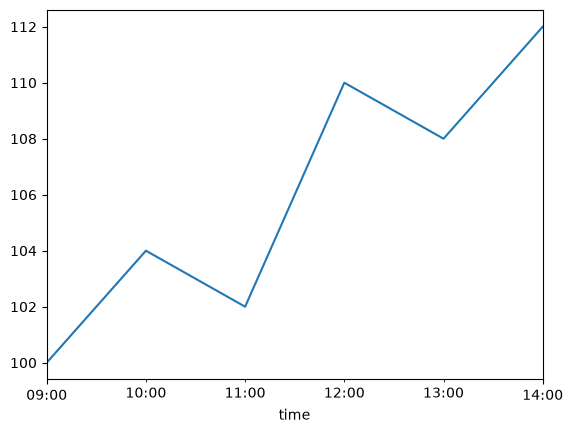

In [2]:
# plot the data
df["temperature"].plot()
plt.show()

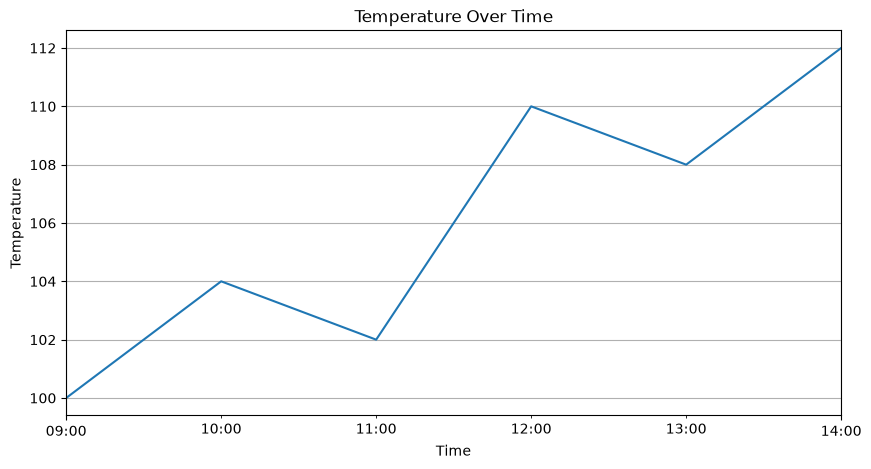

In [3]:
# Improve the plot
df["temperature"].plot(figsize = (10,5))
plt.title("Temperature Over Time")
plt.xlabel("Time")
plt.ylabel("Temperature")
plt.grid(True)
plt.show()


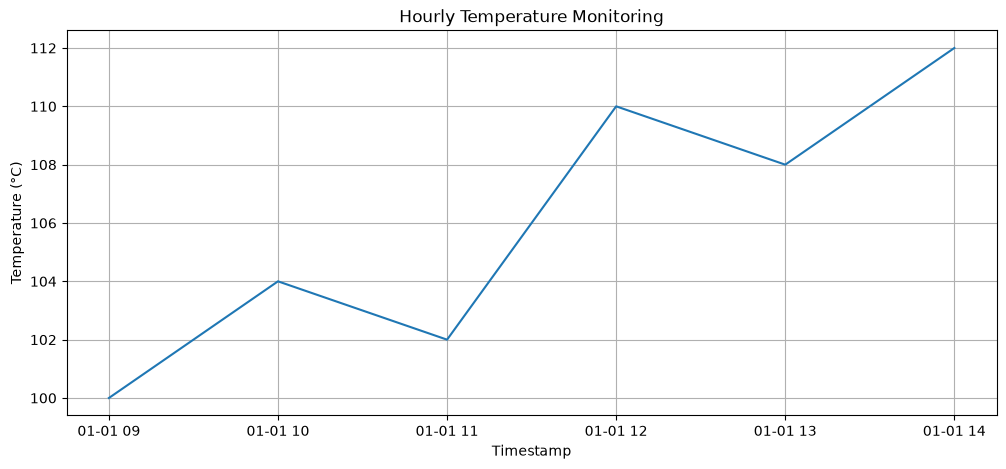

In [4]:
# using another way
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df.index, df["temperature"])

ax.set_title("Hourly Temperature Monitoring")
ax.set_xlabel("Timestamp")
ax.set_ylabel("Temperature (°C)")
ax.grid(True)

plt.show()

In [5]:
df["pressure"] = [20, 21, 19, 23, 22, 24]

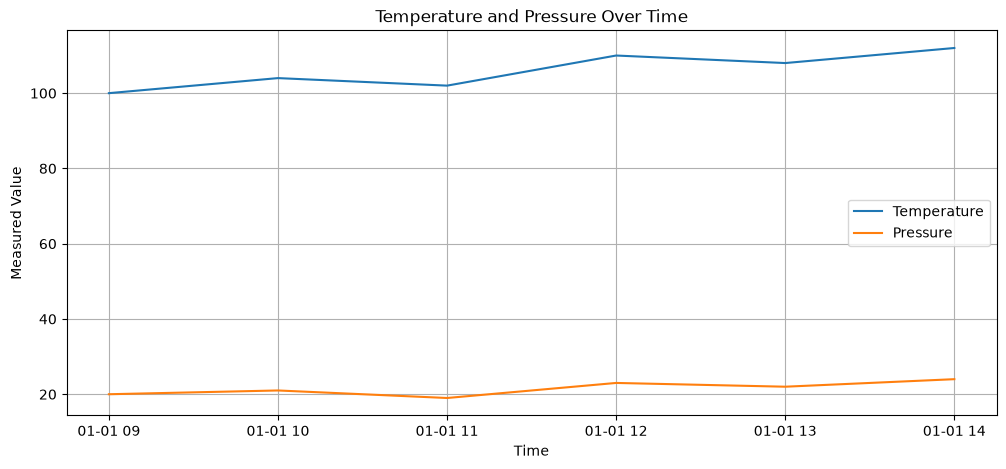

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df.index, df["temperature"], label="Temperature")
ax.plot(df.index, df["pressure"], label="Pressure")

ax.set_title("Temperature and Pressure Over Time")
ax.set_xlabel("Time")
ax.set_ylabel("Measured Value")
ax.legend()
ax.grid(True)

plt.show()

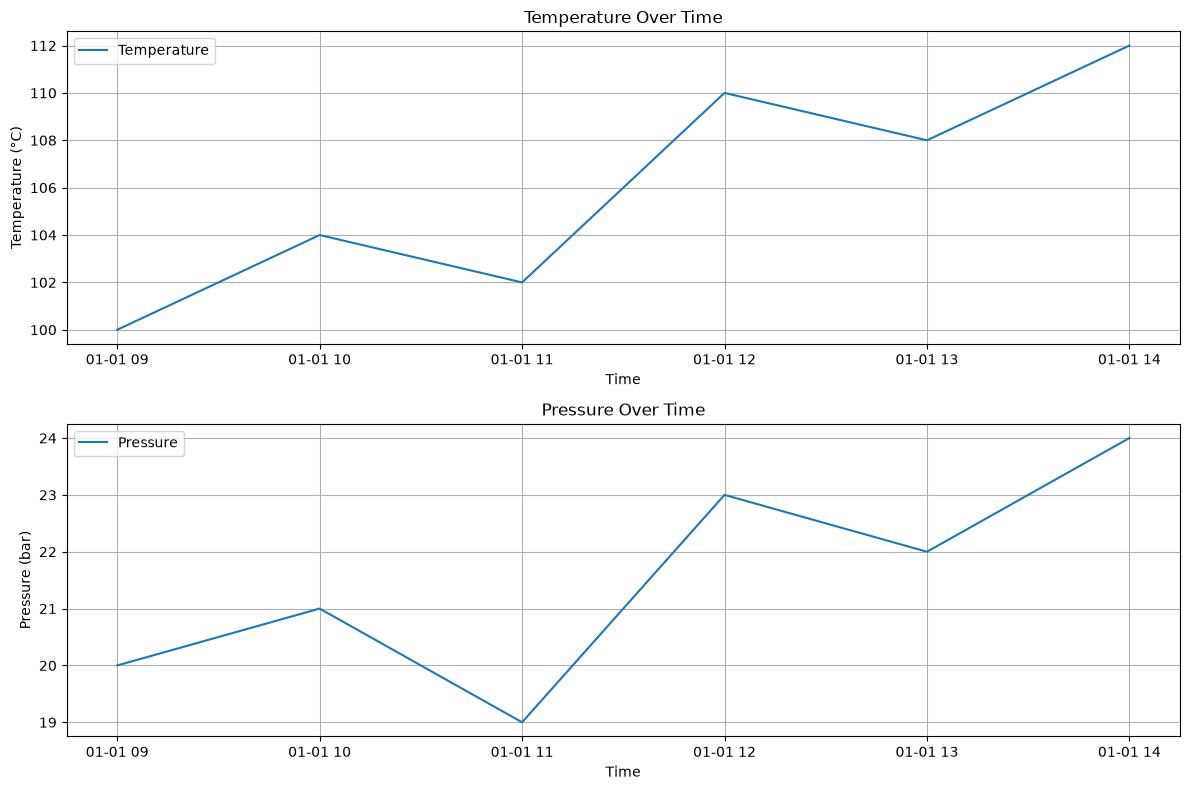

In [7]:
# Stacked plot
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8)
)

# First subplot: temperature
axes[0].plot(df.index, df["temperature"], label="Temperature")
axes[0].set_title("Temperature Over Time")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend()
axes[0].grid(True)

# Second subplot: pressure
axes[1].plot(df.index, df["pressure"], label="Pressure")
axes[1].set_title("Pressure Over Time")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Pressure (bar)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [8]:
# Calculating rolling mean
df["rolling_mean"] = df["temperature"].rolling(window=3).mean()
df

,temperature,pressure,rolling_mean
time,,,
2026-01-01 09:00:00,100,20,NaN
2026-01-01 10:00:00,104,21,NaN
2026-01-01 11:00:00,102,19,102.000000
2026-01-01 12:00:00,110,23,105.333333
2026-01-01 13:00:00,108,22,106.666667
2026-01-01 14:00:00,112,24,110.000000


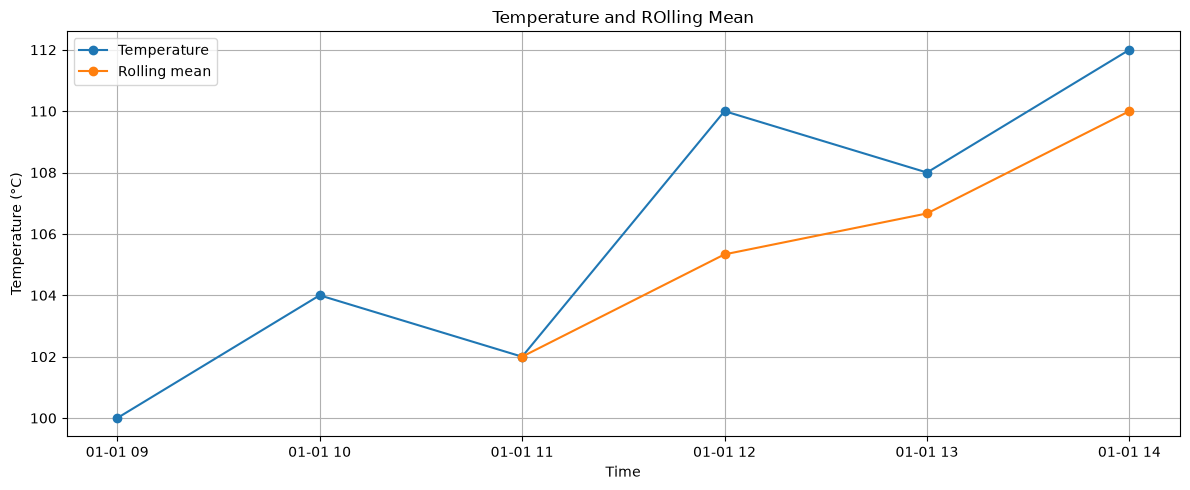

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df.index,
    df["temperature"],
    label = "Temperature",
    marker = 'o'
)

ax.plot(
    df.index,
    df["rolling_mean"],
    label = "Rolling mean",
    marker = "o"
)

ax.set_title("Temperature and ROlling Mean")
ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

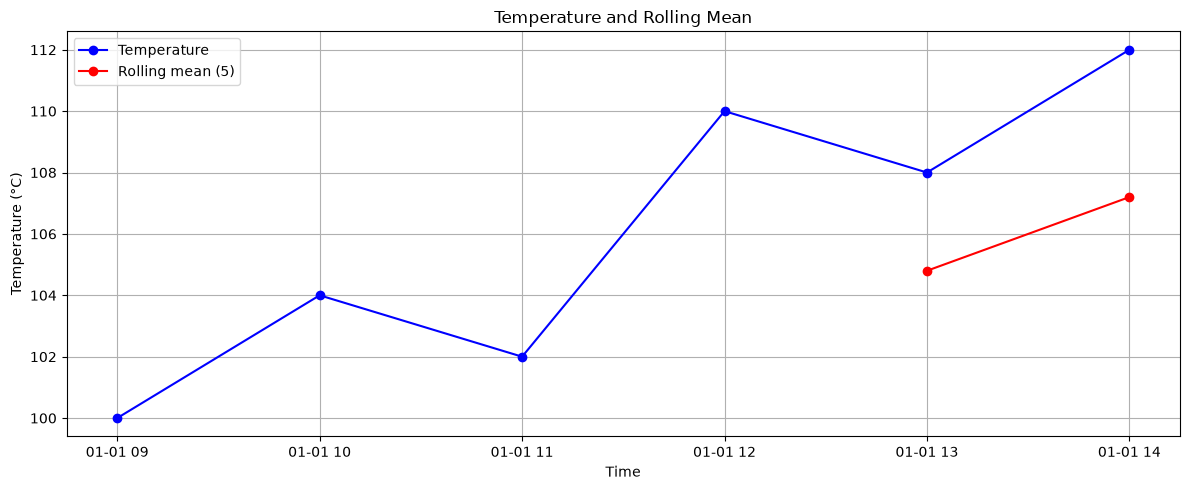

In [10]:
# For the 5 rolling mean
df["rolling_mean_5"] = (
    df["temperature"].rolling(window=5).mean()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df.index,
    df["temperature"],
    label = "Temperature",
    marker = 'o',
    color = 'blue'
)
ax.plot(
    df.index,
    df["rolling_mean_5"],
    label = "Rolling mean (5)",
    marker = "o",
    color = "red"
)

ax.set_title("Temperature and Rolling Mean")
ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()
#

In [11]:
# Comparing time series frequencies

df_daily = df["temperature"].resample("D").mean()
print(df_daily)

time
2026-01-01    106.0
Freq: D, Name: temperature, dtype: float64


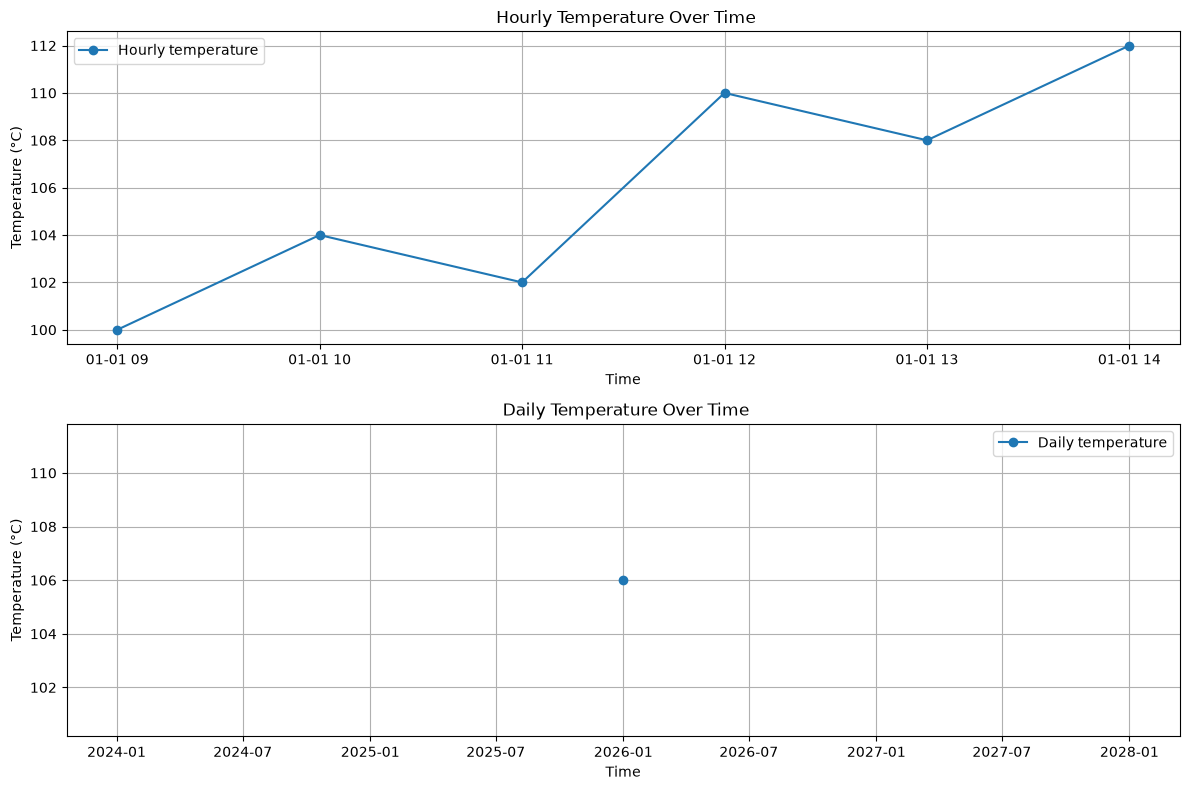

In [12]:
# compare hurly and daily data

fig, ax = plt.subplots(2,1, figsize=(12, 8))

ax[0].plot(
    df.index,
    df["temperature"],
    label = "Hourly temperature",
    marker = 'o'
)
ax[1].plot(
    df_daily.index,
    df_daily,  # Series not a dataframe
    label = "Daily temperature",
    marker = 'o'
)

ax[0].set_title(" Hourly Temperature Over Time")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Temperature (°C)")
ax[0].legend()
ax[0].grid(True)

ax[1].set_title(" Daily Temperature Over Time")
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Temperature (°C)")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()


In [13]:
print(type(df_daily))
print(df_daily)
print(df_daily.columns if isinstance(df_daily, pd.DataFrame) else df_daily.name)

<class 'pandas.Series'>
time
2026-01-01    106.0
Freq: D, Name: temperature, dtype: float64
temperature


In [14]:
# Creating a longer dataset
# 90 data points

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dates = pd.date_range(
    start="2026-01-01",
    periods=90,
    freq="D"
)

df_long = pd.DataFrame(
    {"temperature": 100 + np.random.randn(90).cumsum()},
    index=dates
)

df_long.index.name = "time"

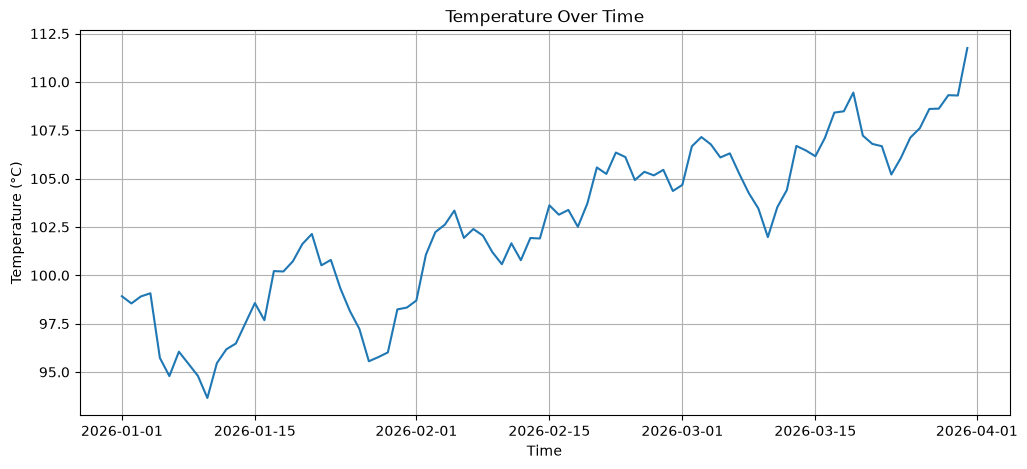

In [15]:
# Plotting the data

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df_long.index,
    df_long["temperature"])

ax.set_title("Temperature Over Time")
ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")
ax.grid(True)

plt.show()


In [16]:
# formatting the date labels
import matplotlib.dates as mdates

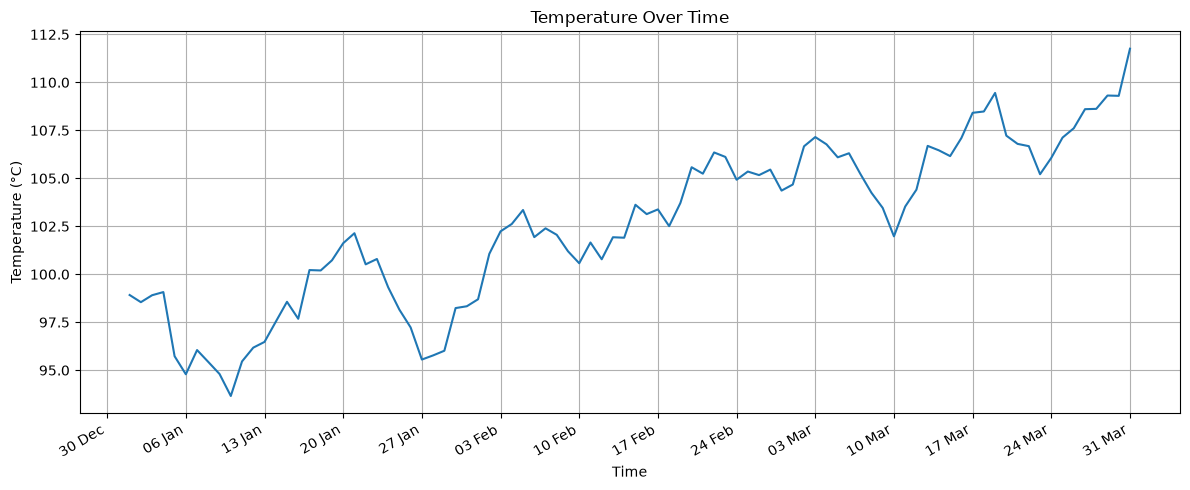

In [17]:
# formatting the dates in tha above plot
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df_long.index,
    df_long["temperature"])
ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax.set_title("Temperature Over Time")
ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")
ax.grid(True)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

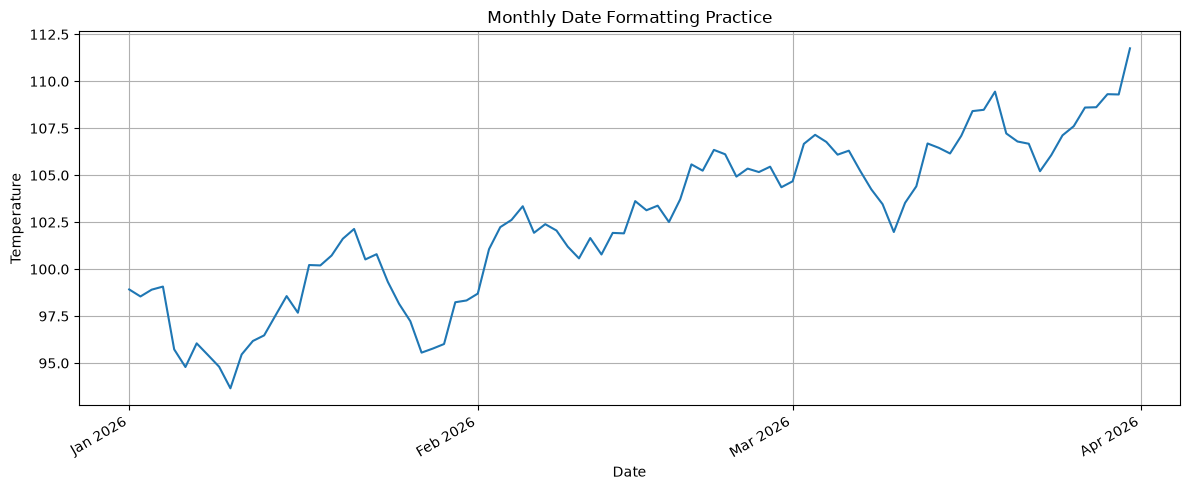

In [18]:
# Date axis formatter

import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_long.index, df_long["temperature"])

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.set_title("Monthly Date Formatting Practice")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature")
ax.grid(True)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

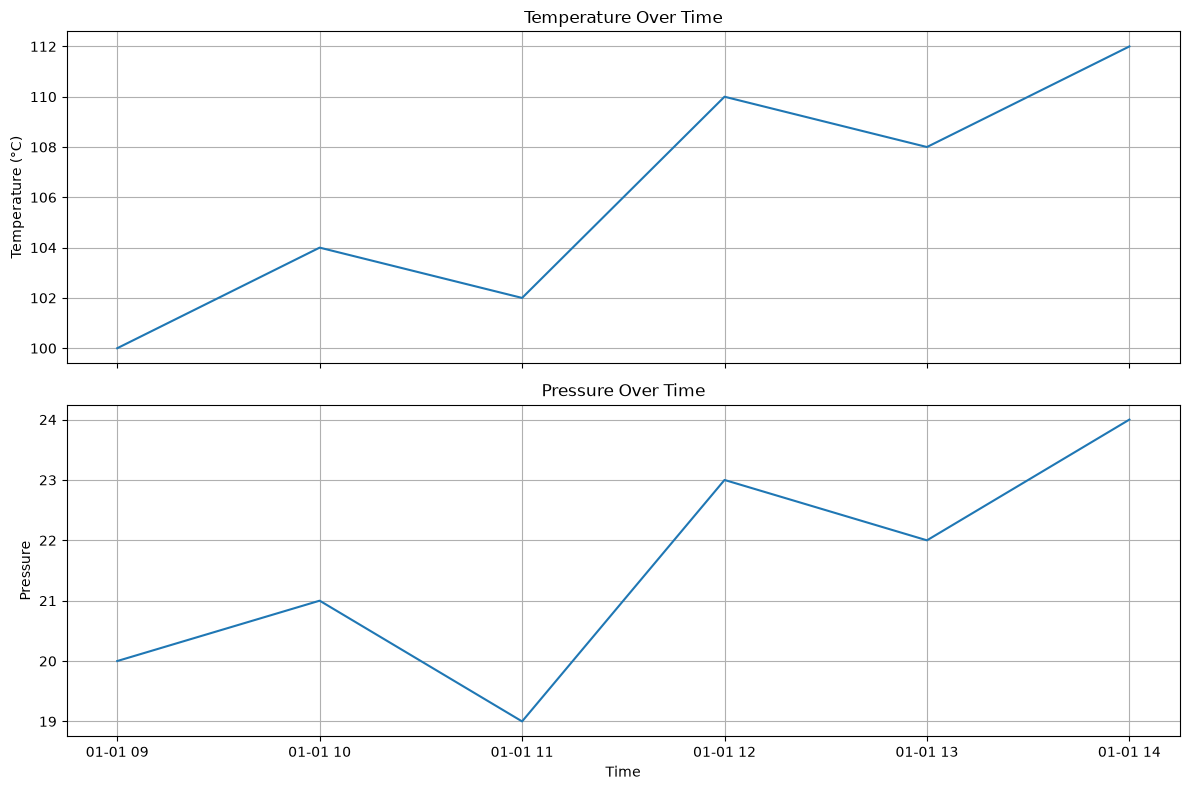

In [19]:
# Sharing X axis
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True
)

axes[0].plot(df.index, df["temperature"])
axes[0].set_title("Temperature Over Time")
axes[0].set_ylabel("Temperature (°C)")
axes[0].grid(True)

axes[1].plot(df.index, df["pressure"])
axes[1].set_title("Pressure Over Time")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Pressure")
axes[1].grid(True)

plt.tight_layout()
plt.show()

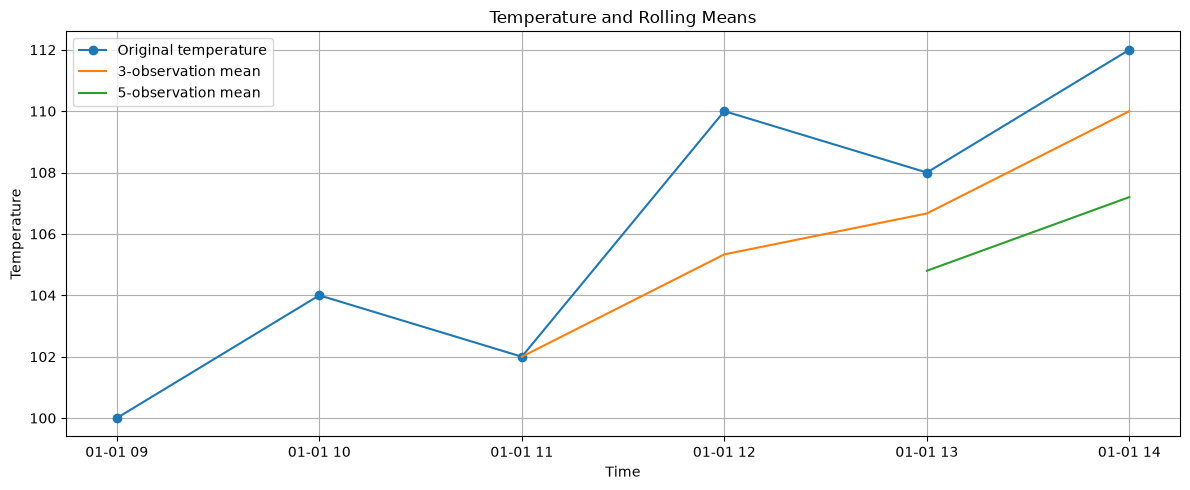

In [20]:
df["rolling_mean_3"] = df["temperature"].rolling(window=3).mean()
df["rolling_mean_5"] = df["temperature"].rolling(window=5).mean()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df.index, df["temperature"],
        label="Original temperature", marker="o")

ax.plot(df.index, df["rolling_mean_3"],
        label="3-observation mean")

ax.plot(df.index, df["rolling_mean_5"],
        label="5-observation mean")

ax.set_title("Temperature and Rolling Means")
ax.set_xlabel("Time")
ax.set_ylabel("Temperature")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

# Chapter 6: Summary and Knowledge Check

## 1. Key Takeaways

1. A time-series line plot displays observations against time, usually with time on the x-axis.
2. Pandas `.plot()` provides a convenient way to visualize a Series or DataFrame.
3. Matplotlib's `fig` represents the figure, while `ax` represents an individual plotting area.
4. `plt.subplots()` creates a figure and one or more Axes objects.
5. When multiple subplots are created, each Axes can be accessed using indexing, such as `axes[0]` and `axes[1]`.
6. The `label` argument and `legend()` identify different plotted series.
7. `sharex=True` shares the x-axis across subplots, while `sharey=True` shares the y-axis.
8. Rolling means can smooth short-term fluctuations, but larger windows may hide sudden changes.
9. Resampling aggregates observations into a different frequency. For example, `.resample("D").mean()` calculates daily means.
10. A Series and a DataFrame require different column-selection syntax.
11. Matplotlib date locators determine where date ticks appear, while date formatters determine how their labels are displayed.
12. A good visualization must be interpreted carefully. Trends, unusual observations, units, aggregation, and smoothing all affect the conclusions that can be drawn.

## 2. Conceptual Questions

Answer these without referring to the lesson notes.

1. What is the difference between a Matplotlib Figure and an Axes object?

2. Why does `fig, ax = plt.subplots(figsize=(12, 5))` return a single Axes object, whereas `fig, axes = plt.subplots(2, 1)` returns an array of Axes objects?

3. What is the purpose of `ax.legend()`?

4. What is the difference between `sharex=True` and `sharey=True`?

5. Why might plotting temperature and pressure on the same y-axis be misleading?

6. What happens to the initial missing values when you change a rolling window from three observations to five observations, using the default settings?

7. Why might a five-observation rolling mean be less responsive to a sudden temperature spike than a three-observation rolling mean?

8. Why does resampling six hourly observations from one day produce only one daily mean?

9. What is the difference between `df["temperature"]` and `df[["temperature"]]`?

10. What is the difference between `mdates.MonthLocator()` and `mdates.DateFormatter("%b %Y")`?

11. Why might a daily mean hide a short-lived abnormal event that is visible in hourly data?

12. Give one example of how time-series visualization could help monitor a chemical engineering process.

## 3. Coding Exercises

Use the original temperature DataFrame from this chapter.

### Exercise 1: Basic plot

Create a line chart of temperature with a figure size of `(12, 5)`, a descriptive title, axis labels, and gridlines.

### Exercise 2: Multiple subplots

Create two vertically stacked subplots showing temperature and pressure. Give each subplot its own title and y-axis label.

### Exercise 3: Rolling means

Create three-observation and five-observation rolling means. Plot both alongside the original temperature series.

Explain which rolling mean responds more slowly to sudden changes and why.

### Exercise 4: Resampling

Resample the temperature data to daily frequency using the mean. Plot the hourly and daily data in separate subplots.

Explain why the number of points differs between the two charts.

### Exercise 5: Date formatting

Using a DataFrame with several months of daily observations, display monthly ticks formatted as `Jan 2026`, `Feb 2026`, and so on.

### Exercise 6: Chart interpretation

Suppose a reactor's measured temperature rises sharply for one hour but returns to normal in the next observation.

Explain how a raw-data plot, a three-observation rolling mean, and a daily mean might represent this event differently.

## 4. Practical Completion Checklist

Before marking the chapter complete, confirm that you can:

- [ ] Create and customize a time-series line plot.
- [ ] Explain the difference between a Figure and an Axes object.
- [ ] Create multiple subplots and access them using indexing.
- [ ] Plot multiple variables with labels and legends.
- [ ] Share axes appropriately across subplots.
- [ ] Overlay rolling statistics on raw observations.
- [ ] Resample time-series data and visualize the aggregated results.
- [ ] Format date ticks and labels.
- [ ] Interpret a chart and explain the limitations of smoothing and aggregation.

## 5. Final Reflection

Time-series visualization is not just about making charts look attractive. It is about communicating how a variable changes over time while preserving important information.

A technically correct chart can still lead to incorrect conclusions if its scale, frequency, units, or smoothing choices are inappropriate.

**Completion criterion:** You should be able to write the plotting code, explain the key functions, and interpret what the resulting chart reveals and what it might conceal.
